# 🍅 SMARTFARM AI — Modèle d'irrigation par Random Forest

**Prototype simulé :** 2 jeunes plants de tomate en pots de 2 L, réservoir de 2 L (niveau mesuré par un JSN-SR04T monté à 50 cm), mini-pompe pilotée par impulsions.
**Serre fermée régulée :** une lampe chauffante (ON < 18 °C, OFF > 21 °C) et un ventilateur d'extraction (ON > 28 °C ou > 85 % d'humidité).

**Objectif du notebook :** partir du fichier `smartfarm_tomato_dataset_v4.csv` et arriver à une Random Forest entraînée, évaluée honnêtement et comparée à une règle simple.

**Plan :**
1. Comprendre le problème et le label
2. Charger et inspecter les données
3. Nettoyer (valeurs manquantes, lectures aberrantes)
4. Explorer visuellement (EDA)
5. Créer des features physiques
6. Séparer train / test **sans tricher**
7. Construire une baseline (un simple `if`)
8. Entraîner la Random Forest
9. Évaluer : métriques, matrice de confusion, faux négatifs
10. Comprendre ce que le modèle a appris
11. Régler les hyperparamètres et le seuil de décision (validation croisée par semaines)
12. Sauvegarder le modèle pour le Raspberry Pi
13. Simuler une décision comme sur le Raspberry Pi

> ⚠️ **À dire au jury :** ce dataset est **synthétique**. Il sert à construire et valider le *pipeline*. Les performances finales devront être mesurées sur des données enregistrées par **vos** capteurs dans **votre** serre.

## 0. Le problème en une phrase

> **« Si on n'arrose pas maintenant, la tomate va-t-elle entrer en stress hydrique dans les 3 prochaines heures ? »**
> → `irrigation_needed = 1` (oui) ou `0` (non)

**Physique derrière le label :** le pot est un **réservoir**, la plante est un **moteur qui consomme**.

```
 réserve d'eau au-dessus du seuil   ← capteur de sol
                                     \
                                      ├─►  la réserve tient-elle 3 h ?  ─►  0 / 1
                                     /
 consommation prévue de la plante   ← lumière, température, humidité de l'air,
                                       heure, âge de la plante
```

**D'où vient le seuil de 70 % ?** Sur l'échelle de votre capteur après calibration :
- **0 %** = substrat sec ; **100 %** = substrat juste après un arrosage complet et égouttage (*capacité au champ*) ;
- le **point de flétrissement** (la plante ne peut plus pomper l'eau) est vers **25 %** ;
- la FAO (bulletin FAO-56) indique qu'une tomate peut consommer **40 %** de l'eau utilisable sans souffrir (p = 0,40).

→ seuil = 100 − 0,40 × (100 − 25) = **70 %**.

**Pourquoi c'est plus intelligent qu'un `if sol < 70` ?**
À 78 % d'humidité, à **23 h** la plante ne boit presque rien : pas besoin d'arroser. À **11 h** un jour de soleil, un plant de quelques semaines dans un pot de 2 L va consommer l'équivalent de 10 à 20 points en 3 h : il faut arroser. Même mesure de sol, décision différente. **C'est là que le ML apporte de la valeur.**

## 1. Importer les bibliothèques

In [1]:
import numpy as np                      # calcul numérique : tableaux, sin, cos, exp...
import pandas as pd                     # tableaux de données (DataFrame)
import matplotlib.pyplot as plt         # graphiques de base
import seaborn as sns                   # graphiques statistiques (histogrammes, heatmaps)
import sklearn                          # scikit-learn : la bibliothèque de ML
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)

print("pandas       :", pd.__version__)
print("scikit-learn :", sklearn.__version__)
sns.set_theme(style="whitegrid")        # style des graphiques

pandas       : 2.2.3
scikit-learn : 1.6.1


🔎 **Ligne par ligne**
- `from sklearn.ensemble import RandomForestClassifier` : on importe seulement la classe dont on a besoin. *Ensemble* = famille des modèles qui combinent plusieurs modèles (ici, plusieurs arbres).
- `from sklearn.metrics import ...` : les fonctions qui **mesurent** la qualité des prédictions. On les détaille à l'étape 9.
- `sns.set_theme(...)` : seulement esthétique.

## 2. Charger le dataset (téléchargement automatique depuis Google Drive)

Le CSV est dans le dossier Drive partagé **« dataset cas ml »**. La cellule le télécharge toute seule : rien à importer à la main.
(Si tu as déjà importé le CSV via l'icône 📁, la cellule l'utilise directement.)

In [2]:
import glob

DOSSIER_DRIVE = "<LIEN_DOSSIER_DRIVE>"

def chercher_csv():
    return sorted(glob.glob("smartfarm_tomato_dataset_v4*.csv")
                  + glob.glob("dataset_cas_ml/**/*.csv", recursive=True))

if not chercher_csv():                       # pas encore dans Colab -> on télécharge le dossier Drive
    !gdown --folder {DOSSIER_DRIVE} -O dataset_cas_ml

fichier = chercher_csv()[0]
print("Fichier utilisé :", fichier)
df = pd.read_csv(fichier, parse_dates=["timestamp"])
print(df.shape)
df.head()

Retrieving folder contents
Processing file <ID> smartfarm_tomato_dataset_v4 (1).csv
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=<ID>
To: /content/dataset_cas_ml/smartfarm_tomato_dataset_v4 (1).csv
100% 2.86M/2.86M [00:00<00:00, 107MB/s]
Download completed
Fichier utilisé : dataset_cas_ml/smartfarm_tomato_dataset_v4 (1).csv
(36288, 16)


,timestamp,cycle,days_after_transplant,air_temp_c,air_humidity_pct,light_lux,soil_raw_adc,soil_moisture_pct,water_level_pct,pump_on,irrigation_l,fan_on,lamp_on,sim_policy,sim_soil_true_pct,irrigation_needed
0,2025-09-01 00:00:00,1,0,24.2,77.2,0,300,100.8,98.1,0,0.0,0,0,seuil_capteur,100.0,0
1,2025-09-01 00:10:00,1,0,24.5,76.2,0,299,101.3,104.8,0,0.0,0,0,seuil_capteur,100.0,0
2,2025-09-01 00:20:00,1,0,24.7,74.9,0,296,102.5,93.1,0,0.0,0,0,seuil_capteur,100.0,0
3,2025-09-01 00:30:00,1,0,24.8,75.2,0,298,101.7,104.9,0,0.0,0,0,seuil_capteur,100.0,0
4,2025-09-01 00:40:00,1,0,24.5,76.3,0,297,102.1,106.7,0,0.0,0,0,seuil_capteur,100.0,0


🔎 **Ligne par ligne**
- `glob.glob(...)` cherche des fichiers dont le nom correspond à un motif : `*` = « n'importe quels caractères », `**` = « dans tous les sous-dossiers ». Comme ça, le nom exact du fichier n'a pas d'importance (même avec un « (1) » ajouté par le navigateur).
- `if not chercher_csv():` : si aucun CSV n'est trouvé, on le télécharge. Sinon, on ne retélécharge pas.
- `!gdown --folder ... -O dataset_cas_ml` : le `!` exécute une **commande du terminal**. `gdown` (déjà installé dans Colab) télécharge tout le dossier Drive dans un dossier `dataset_cas_ml`. Les `{ }` insèrent la variable Python `DOSSIER_DRIVE` dans la commande.
- ⚠️ Le dossier Drive doit être partagé en **« Tous les utilisateurs disposant du lien »**, sinon `gdown` affiche *Permission denied*.
- `pd.read_csv(...)` lit le fichier texte et crée un **DataFrame** (un tableau : lignes = mesures, colonnes = variables).
- `parse_dates=["timestamp"]` : sans ça, la date serait lue comme du **texte**. Avec, pandas comprend que c'est un instant, et on pourra extraire l'heure, la semaine, etc.
- `df.shape` → `(36288, 16)` : **36 288 lignes** = 6 plantations de jeunes plants × 42 jours × 144 mesures/jour (une toutes les 10 min). Les 6 plantations sont réparties de septembre à juin pour couvrir toutes les saisons.

## 3. Premier regard sur les données

In [ ]:
df.info()

💡 **À remarquer :** `air_temp_c` et `air_humidity_pct` ont **moins de valeurs non nulles** que les autres colonnes. Ce sont des **lectures ratées du DHT22** (ce capteur échoue de temps en temps : erreur de checksum, câble long…). On les traite à l'étape 4.

In [ ]:
df.describe().T.round(1)

💡 **Ce que `describe()` révèle :**
- `soil_moisture_pct` a un **min ≈ −205 %** et un **max ≈ 228 %** : physiquement **impossible**. Ce sont des parasites sur la liaison série Arduino → Raspberry Pi (lecture brute de 0 ou de 1023).
- `light_lux` plafonne à **54 612** : c'est la **saturation du BH1750** en réglage par défaut (65535 / 1,2). En plein soleil d'été, le capteur « ne voit plus » au-delà.
- `soil_moisture_pct` dépasse parfois 100 % : normal juste après un arrosage, avant que l'excès d'eau ne s'égoutte.

### Les 4 familles de colonnes : lesquelles a-t-on le droit d'utiliser ?

| Famille | Colonnes | Utilisable comme feature ? |
|---|---|---|
| **Capteurs** | `air_temp_c`, `air_humidity_pct` (DHT22), `light_lux` (BH1750), `soil_moisture_pct` (sonde de sol calibrée), `days_after_transplant` (date de plantation connue) | ✅ **Oui** : le Raspberry Pi les connaît au moment de décider |
| **Doublon brut** | `soil_raw_adc` | ➖ Même information que `soil_moisture_pct` avant calibration |
| **Actionneurs / sécurité** | `pump_on`, `irrigation_l`, `fan_on`, `lamp_on`, `water_level_pct` | ❌ **Non** : ce sont des **conséquences de décisions** (ou une règle de sécurité séparée pour le réservoir). Note : un arrosage **à la main** n'apparaît pas dans `irrigation_l`, comme dans la réalité |
| **Simulation** | `sim_policy`, `sim_soil_true_pct`, `cycle` | ❌ **Interdit** : n'existera jamais sur le vrai système |
| **Label** | `irrigation_needed` | 🎯 Ce qu'on veut prédire |

> `sim_soil_true_pct` est la **vraie** humidité du sol, connue seulement parce que c'est une simulation. Elle sert à comprendre l'erreur du capteur, pas à entraîner le modèle.

## 4. Nettoyage : valeurs manquantes et lectures aberrantes

In [3]:
df.isna().sum()

,0
timestamp,0
cycle,0
days_after_transplant,0
air_temp_c,354
air_humidity_pct,354
light_lux,0
soil_raw_adc,0
soil_moisture_pct,0
water_level_pct,173
pump_on,0


In [4]:
# Lectures impossibles du capteur de sol : 0 ou 1023 = parasite sur la liaison série
glitch = df["soil_raw_adc"].isin([0, 1023]) | ~df["soil_moisture_pct"].between(-20, 140)
print("Lectures de sol aberrantes :", glitch.sum())

df.loc[glitch, ["soil_raw_adc", "soil_moisture_pct"]] = np.nan   # on les transforme en "manquant"

Lectures de sol aberrantes : 49


🔎 **Ligne par ligne**
- `df["soil_raw_adc"].isin([0, 1023])` : vrai quand la lecture brute vaut exactement 0 ou 1023 (les deux bornes de l'ADC 10 bits). Un vrai sol ne donne jamais ça.
- `~df["soil_moisture_pct"].between(-20, 140)` : `between` teste si la valeur est dans l'intervalle ; `~` veut dire **NON**. Donc : vrai si la valeur est **hors** de [−20, 140].
- `|` = **OU** logique.
- `df.loc[glitch, [...]] = np.nan` : sur les lignes aberrantes, on remplace la valeur par `NaN` (*Not a Number* = manquant). On ne **supprime pas** la ligne, car les autres capteurs y sont valides.

In [5]:
capteurs = ["air_temp_c", "air_humidity_pct", "soil_raw_adc", "soil_moisture_pct", "water_level_pct"]
df[capteurs] = df.groupby("cycle")[capteurs].ffill()

print(df[capteurs].isna().sum())

air_temp_c           0
air_humidity_pct     0
soil_raw_adc         0
soil_moisture_pct    0
water_level_pct      0
dtype: int64


🔎 **Pourquoi `ffill` (*forward fill*) et pas la moyenne ?**

`ffill` remplace un trou par **la dernière valeur valide**. C'est exactement ce que fera le Raspberry Pi en temps réel : si le DHT22 rate une lecture, on garde la précédente.

- ❌ Remplacer par la **moyenne** du dataset : en pleine nuit d'hiver, on mettrait 21 °C au lieu de 9 °C. Absurde physiquement.
- ❌ **Interpoler** entre la valeur d'avant et celle d'après : utilise une valeur **future**, que le Pi ne connaît pas au moment de décider. C'est une petite **fuite de données**.
- `groupby("cycle")` : on ne remplit pas le début du cycle 2 avec une valeur de la fin du cycle 1 (5 mois plus tôt !).

## 5. Explorer visuellement (EDA)

### 5.1 Une semaine de la serre, vue par les capteurs

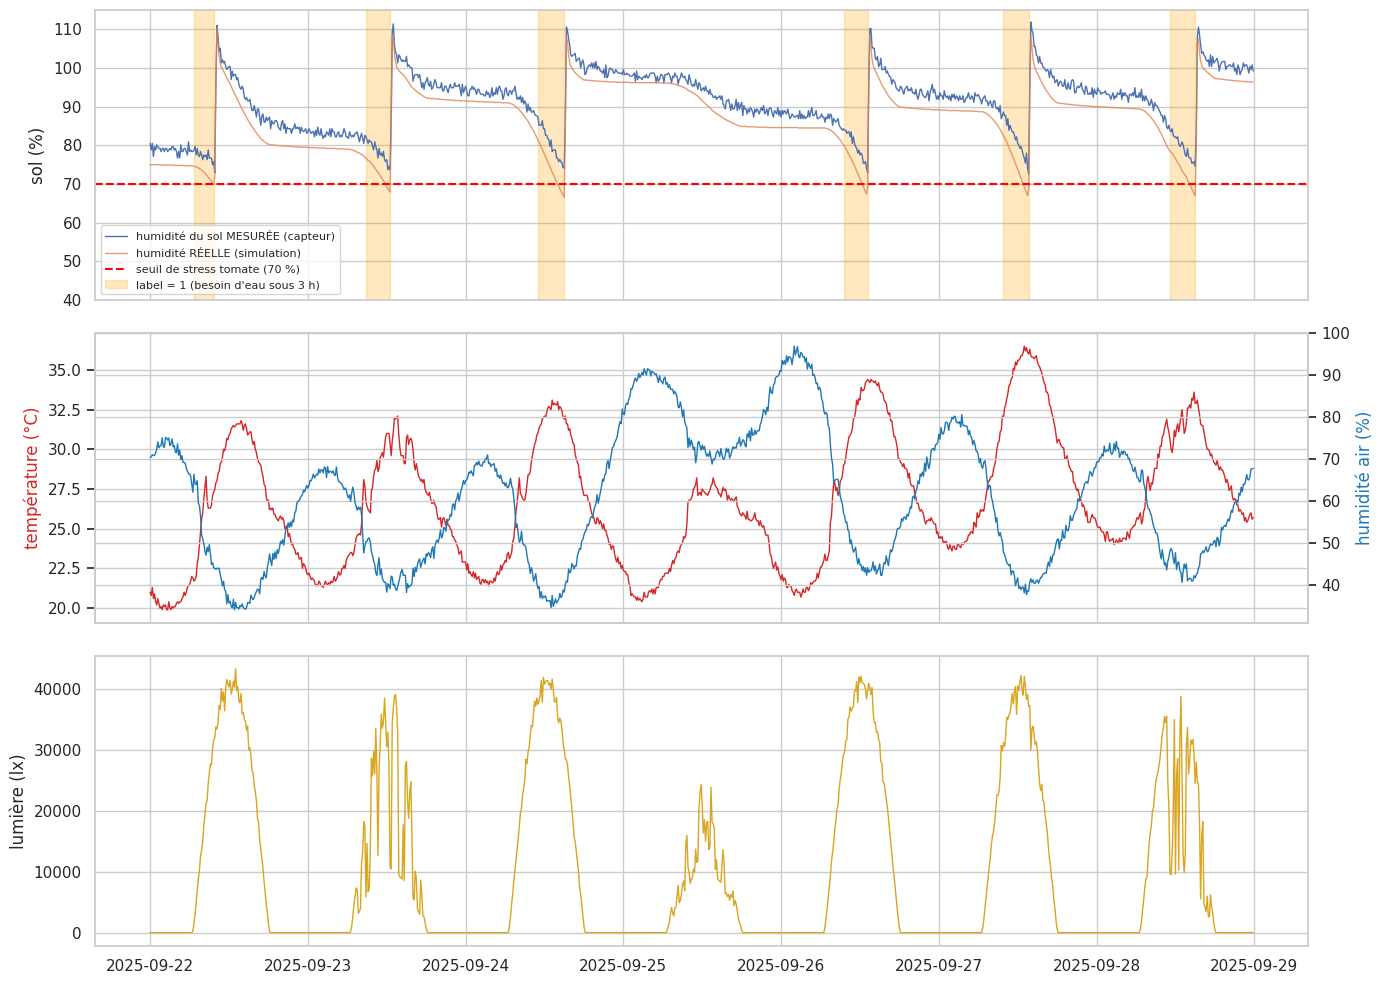

In [6]:
s = df[(df["timestamp"] >= "2025-09-22") & (df["timestamp"] < "2025-09-29")]

fig, ax = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

ax[0].plot(s["timestamp"], s["soil_moisture_pct"], lw=1, label="humidité du sol MESURÉE (capteur)")
ax[0].plot(s["timestamp"], s["sim_soil_true_pct"], lw=1, alpha=0.8, label="humidité RÉELLE (simulation)")
ax[0].axhline(70, color="red", ls="--", label="seuil de stress tomate (70 %)")
ax[0].fill_between(s["timestamp"], 40, 115, where=s["irrigation_needed"] == 1,
                   color="orange", alpha=0.25, label="label = 1 (besoin d'eau sous 3 h)")
ax[0].set_ylim(40, 115); ax[0].set_ylabel("sol (%)"); ax[0].legend(loc="lower left", fontsize=8)

ax[1].plot(s["timestamp"], s["air_temp_c"], color="tab:red", lw=1)
ax[1].set_ylabel("température (°C)", color="tab:red")
ax1b = ax[1].twinx()
ax1b.plot(s["timestamp"], s["air_humidity_pct"], color="tab:blue", lw=1)
ax1b.set_ylabel("humidité air (%)", color="tab:blue")

ax[2].plot(s["timestamp"], s["light_lux"], color="goldenrod", lw=1)
ax[2].set_ylabel("lumière (lx)")
plt.tight_layout(); plt.show()

💡 **Comment lire ce graphique**
- **Le sol descend en « marches d'escalier » le jour et reste plat la nuit.** La plante transpire quand il y a de la lumière (stomates ouverts) et quasiment pas la nuit.
- **Les sauts vers le haut** sont les arrosages. Juste après, l'humidité dépasse brièvement 100 %, puis l'excès s'égoutte.
- **Les zones orange (label = 1) commencent AVANT que la courbe réelle passe sous 70 %.** C'est l'anticipation : à 11 h, même à 80 %, la réserve ne tiendra pas jusqu'à 14 h.
- **L'écart entre courbe mesurée et courbe réelle** est l'erreur du capteur : non-linéarité de la sonde capacitive et dérive avec la température. Une calibration en 2 points ne corrige pas tout.
- **La température monte avec la lumière, et l'humidité de l'air baisse quand il fait chaud** : les deux courbes sont en opposition.
- **Change les dates pour explorer.** En hiver (par exemple `"2025-12-15"` → `"2025-12-22"`), tu verras la **lampe chauffante** : la nuit, la température reste autour de 18-21 °C au lieu de tomber vers 10 °C, et le BH1750 affiche **~2 000 lx en pleine nuit** (il voit la lampe). Au printemps (`"2026-04-13"`), la lumière **plafonne à 54 612 lx** (saturation du BH1750) et la température fait un **zigzag entre 25 et 28 °C** : c'est le ventilateur qui s'allume à 28 °C et s'éteint à 25 °C (thermostat avec *hystérésis*).

### 5.2 Répartition des classes

In [7]:
print(df["irrigation_needed"].value_counts())
print(df["irrigation_needed"].value_counts(normalize=True).round(3))

irrigation_needed
0    23688
1    12600
Name: count, dtype: int64
irrigation_needed
0    0.653
1    0.347
Name: proportion, dtype: float64


💡 **Le piège de l'accuracy.** Environ **65 %** des lignes sont des « 0 ». Un modèle stupide qui répond **toujours 0** aurait donc ~65 % d'accuracy… et ne déclencherait **jamais** l'arrosage. C'est pourquoi on regardera surtout le **recall** et le **F1** de la classe 1 (étape 9).

### 5.3 Le capteur de sol suffit-il à séparer les classes ?

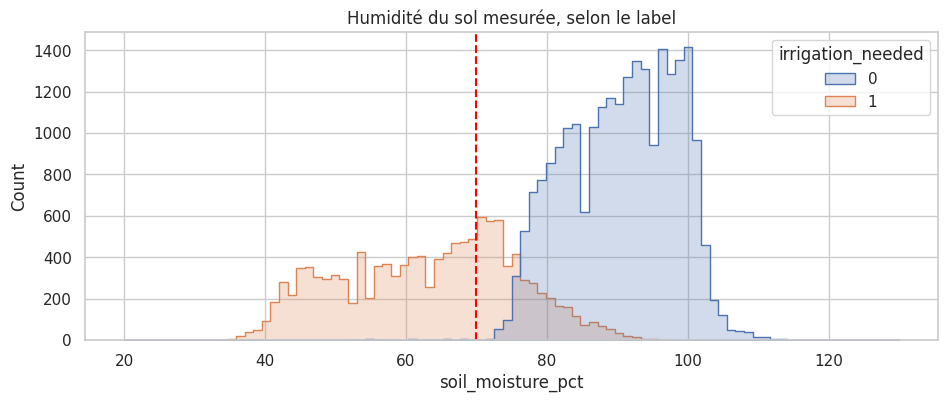

In [8]:
plt.figure(figsize=(11, 4))
sns.histplot(data=df, x="soil_moisture_pct", hue="irrigation_needed", bins=90,
             binrange=(20, 130), element="step", stat="count")
plt.axvline(70, color="red", ls="--")
plt.title("Humidité du sol mesurée, selon le label")
plt.show()

💡 **Graphique clé pour le jury.**
- En dessous de ~70 % : presque que des 1 (plante déjà en stress → arroser, évidemment).
- Au-dessus de ~95 % : presque que des 0 (pot plein).
- **Entre ~70 et ~90 % : les deux classes se chevauchent.** Avec le seul capteur de sol, impossible de trancher. Il faut savoir **combien la plante va boire** dans les 3 prochaines heures, donc utiliser la lumière, la température, l'heure, la taille de la plante… C'est exactement le travail de la Random Forest.

### 5.4 Corrélations

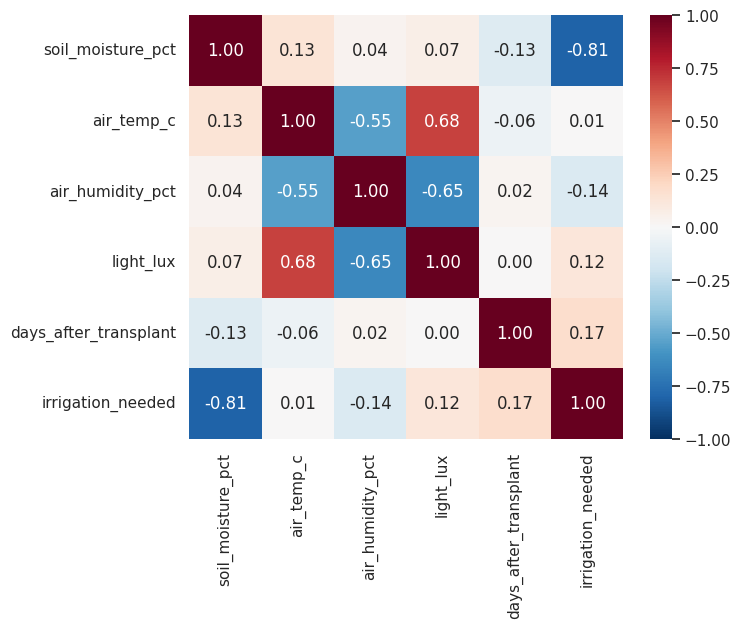

In [9]:
cols = ["soil_moisture_pct", "air_temp_c", "air_humidity_pct", "light_lux",
        "days_after_transplant", "irrigation_needed"]
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.show()

💡 **Lecture**
- `soil_moisture_pct` ↔ label : forte corrélation **négative** (plus le sol est humide, moins on a besoin d'arroser). Logique.
- `air_temp_c` ↔ `air_humidity_pct` : négative. Quand l'air chauffe, il peut contenir plus de vapeur, donc l'humidité **relative** baisse.
- ⚠️ La corrélation ne mesure que les relations **linéaires et une variable à la fois**. Une variable faiblement corrélée (l'heure, par exemple) peut être très utile **en combinaison** avec le sol. Les arbres de décision savent exploiter ces combinaisons.

## 6. Feature engineering : traduire la physique en colonnes

In [10]:
heure = df["timestamp"].dt.hour + df["timestamp"].dt.minute / 60
df["hour_sin"] = np.sin(2 * np.pi * heure / 24)
df["hour_cos"] = np.cos(2 * np.pi * heure / 24)

es = 0.6108 * np.exp(17.27 * df["air_temp_c"] / (df["air_temp_c"] + 237.3))   # kPa
df["vpd_kpa"] = es * (1 - df["air_humidity_pct"] / 100)

df["soil_slope_1h"] = df.groupby("cycle")["soil_moisture_pct"].diff(6)
df["light_mean_1h"] = (df.groupby("cycle")["light_lux"]
                         .transform(lambda x: x.rolling(6, min_periods=1).mean()))

df = df.dropna(subset=["soil_slope_1h"]).reset_index(drop=True)
df[["timestamp", "hour_sin", "hour_cos", "vpd_kpa", "soil_slope_1h", "light_mean_1h"]].head()

,timestamp,hour_sin,hour_cos,vpd_kpa,soil_slope_1h,light_mean_1h
0,2025-09-01 01:00:00,0.258819,0.965926,0.663220,-0.8,0.0
1,2025-09-01 01:10:00,0.300706,0.953717,0.664384,1.2,0.0
2,2025-09-01 01:20:00,0.342020,0.939693,0.631164,-1.7,0.0
3,2025-09-01 01:30:00,0.382683,0.923880,0.607005,0.8,0.0
4,2025-09-01 01:40:00,0.422618,0.906308,0.628881,0.0,0.0


🔎 **Chaque feature et son sens physique**

| Feature | Calcul | Sens physique |
|---|---|---|
| `hour_sin`, `hour_cos` | l'heure placée sur un cercle | Pour le modèle, **23 h 50 et 0 h 10 doivent être proches**. Avec l'heure brute (23,8 et 0,2), elles paraissent éloignées. Sur un cercle (comme une horloge), elles sont voisines. |
| `vpd_kpa` | *déficit de pression de vapeur* = pression de vapeur saturante − pression réelle | **La « soif de l'air ».** Air chaud et sec → VPD élevé → l'air « aspire » l'eau des feuilles → la plante transpire plus. C'est LA variable des agronomes de serre. |
| `soil_slope_1h` | humidité du sol maintenant − il y a 1 h (6 mesures) | **La vitesse à laquelle le réservoir se vide.** Une pente de −3 points/h dit « elle boit vite ». |
| `light_mean_1h` | moyenne de la lumière sur la dernière heure | Lisse les passages de nuages : un nuage de 5 min ne change pas la consommation de la plante. |

- `es = 0.6108 * np.exp(...)` : la **formule de Tetens**, qui donne la pression de vapeur saturante (kPa) en fonction de la température.
- `.diff(6)` : différence avec la valeur 6 lignes plus haut (6 × 10 min = 1 h). Faite **par cycle** (`groupby`).
- `.rolling(6, min_periods=1).mean()` : moyenne glissante sur les 6 dernières valeurs. Elle utilise **uniquement le passé**, donc pas de fuite.
- `dropna(subset=["soil_slope_1h"])` : les 6 premières lignes de chaque cycle n'ont pas de « il y a 1 h » ; on les retire.

## 7. Séparer les features (X) et le label (y)

In [11]:
FEATURES = ["soil_moisture_pct", "air_temp_c", "air_humidity_pct", "light_lux", "light_mean_1h",
            "vpd_kpa", "hour_sin", "hour_cos", "soil_slope_1h", "days_after_transplant"]

X = df[FEATURES]
y = df["irrigation_needed"]
print("X :", X.shape, "| y :", y.shape)

X : (36252, 10) | y : (36252,)


🔎 `X` (majuscule : par convention une **matrice**) contient les 10 colonnes d'entrée. `y` (minuscule : un **vecteur**) contient la réponse attendue.

> **Normalisation ?** Pas nécessaire pour une Random Forest. Un arbre pose des questions du type « `light_lux` > 20 000 ? ». Que la lumière soit en lux ou en klux, la question et sa réponse sont les mêmes. Les modèles basés sur des **distances** ou des **gradients** (KNN, SVM, régression logistique, réseaux de neurones) ont besoin de normalisation ; les arbres non.

## 8. Séparer train / test **par semaines**

**Pourquoi pas un `train_test_split` aléatoire ?** Deux mesures prises à 10 minutes d'écart sont presque identiques. Avec un tirage aléatoire, la mesure de 10 h 00 serait dans le train et celle de 10 h 10 dans le test : le modèle aurait **déjà vu la réponse**, à quelques décimales près. Le score serait trop beau, et faux.

**Solution :** on met des **semaines entières** dans le test. Le modèle sera évalué sur des semaines qu'il n'a **jamais vues**, avec d'autres météos et d'autres façons d'arroser.

In [12]:
semaine = df["timestamp"].dt.isocalendar().week.astype(int)
est_test = (semaine % 5 == 0)          # 1 semaine sur 5 → test (~20 %)

X_train, X_test = X[~est_test], X[est_test]
y_train, y_test = y[~est_test], y[est_test]

print(f"Train : {len(X_train):>6} lignes | part de 1 : {y_train.mean():.3f}")
print(f"Test  : {len(X_test):>6} lignes | part de 1 : {y_test.mean():.3f}")
print("Semaines de test :", sorted(semaine[est_test].unique().tolist()))

Train :  29208 lignes | part de 1 : 0.341
Test  :   7044 lignes | part de 1 : 0.374
Semaines de test : [5, 10, 15, 20, 40, 45, 50]


🔎 **Ligne par ligne**
- `.dt.isocalendar().week` : numéro de semaine ISO (1 à 52).
- `semaine % 5 == 0` : `%` est le **modulo** (reste de la division). Une semaine sur 5, réparties dans les deux cycles et dans toutes les saisons, part dans le test.
- `X[~est_test]` : toutes les lignes qui **ne sont pas** dans le test.
- **Vérifie la part de 1** dans le train et le test : elles doivent être du même ordre. Ici, la façon d'arroser change d'une semaine à l'autre, donc certaines semaines sont beaucoup plus « sèches » que d'autres. Un test rempli de semaines sèches ne serait pas représentatif. (Essaie `% 5 == 3` pour voir la différence.)

> **Le test est sacré.** On n'y touche que pour la mesure finale. Tous les réglages (seuil de la baseline, hyperparamètres) se font sur le **train**. Sinon, on « apprend le test », et le score annoncé au jury serait optimiste.

## 9. La baseline : ce que ferait un simple `if`

Avant le ML, on mesure la meilleure **règle simple** : `arroser si sol < S`. Si la Random Forest ne fait pas mieux, elle ne sert à rien.

In [13]:
seuils = np.arange(60, 100, 0.5)
f1_train = [f1_score(y_train, (X_train["soil_moisture_pct"] < S).astype(int)) for S in seuils]
S_best = seuils[int(np.argmax(f1_train))]
print("Meilleur seuil trouvé sur le TRAIN :", S_best, "%")

y_pred_base = (X_test["soil_moisture_pct"] < S_best).astype(int)

Meilleur seuil trouvé sur le TRAIN : 76.0 %


🔎 **Ligne par ligne**
- `np.arange(60, 100, 0.5)` : tous les seuils candidats 60 ; 60,5 ; 61 ; … ; 99,5.
- `[... for S in seuils]` : une *list comprehension*. Pour chaque seuil, on prédit `1` si sol < S et on calcule le F1 **sur le train**.
- `np.argmax(...)` : la position du meilleur F1, d'où le meilleur seuil.
- On applique ensuite ce seuil **figé** au test.

💡 Le meilleur seuil est **au-dessus de 70 %** (vers 75-78 %). La règle simple « prend de la marge » pour couvrir les jours de forte consommation, au prix d'arrosages inutiles la nuit.

## 10. Entraîner la Random Forest

**Ce qui se passe pendant `fit()`.** Pour chacun des 100 arbres :
1. **Bootstrap :** on tire au hasard, *avec remise*, autant de lignes qu'il y en a dans le train. Chaque arbre voit donc un échantillon un peu différent ; environ 37 % des lignes ne sont pas tirées.
2. **Construction de l'arbre :** à chaque nœud, on choisit **au hasard un sous-ensemble de features**. Parmi elles, on cherche la question (« `soil_moisture_pct` < 76,3 ? ») qui sépare le mieux les 0 et les 1, c'est-à-dire qui rend les groupes les plus « purs » (indice de **Gini**).
3. On recommence dans chaque branche jusqu'à une condition d'arrêt (profondeur max, taille min des feuilles).

**Pendant `predict()`** : chaque arbre vote 0 ou 1, et la forêt donne la **majorité**.

**Analogie :** demander un diagnostic à 100 agronomes qui ont chacun vu des saisons un peu différentes et regardé des indices différents. Chacun peut se tromper, mais **leurs erreurs ne sont pas les mêmes**, et le vote les fait se compenser.

In [14]:
rf = RandomForestClassifier(
    n_estimators=100,       # nombre d'arbres
    max_depth=12,           # profondeur max de chaque arbre (limite la mémorisation et la taille du modèle)
    min_samples_leaf=5,     # chaque feuille contient au moins 5 exemples (évite d'apprendre le bruit)
    n_jobs=-1,              # utilise tous les cœurs du processeur
    random_state=42,        # même hasard à chaque exécution -> résultats reproductibles
)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
print("Entraînement terminé.")

Entraînement terminé.


🔎 **Les hyperparamètres choisis ici sont un point de départ raisonnable**, pas le résultat d'une optimisation. On les ajustera à l'étape suivante du projet (GridSearchCV).
- `max_depth=12` et `min_samples_leaf=5` jouent aussi sur la **taille du fichier du modèle**, un point important pour un Raspberry Pi 3 avec 1 Go de RAM.
- `random_state=42` : le nombre lui-même n'a aucune importance ; ce qui compte, c'est de le **fixer**.

## 11. Évaluer : baseline vs Random Forest

In [15]:
def evaluer(nom, y_vrai, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_vrai, y_pred).ravel()
    return {"modèle": nom,
            "accuracy": accuracy_score(y_vrai, y_pred),
            "precision": precision_score(y_vrai, y_pred),
            "recall": recall_score(y_vrai, y_pred),
            "F1": f1_score(y_vrai, y_pred),
            "faux négatifs (soif ignorée)": fn,
            "faux positifs (arrosage inutile)": fp}

resultats = pd.DataFrame([evaluer(f"Baseline : sol < {S_best} %", y_test, y_pred_base),
                          evaluer("Random Forest", y_test, y_pred_rf)])
resultats.round(3)

,modèle,accuracy,precision,recall,F1,faux négatifs (soif ignorée),faux positifs (arrosage inutile)
0,Baseline : sol < 76.0 %,0.934,0.968,0.851,0.906,391,75
1,Random Forest,0.962,0.972,0.926,0.948,196,71


🔎 **Les 4 cases de la matrice de confusion, version serre**

| | Le modèle dit **0** (ne pas arroser) | Le modèle dit **1** (arroser) |
|---|---|---|
| **Réalité 0** | ✅ Vrai négatif | ⚠️ **Faux positif** : arrosage inutile. Gaspillage d'eau, et en serre fermée, excès d'humidité → asphyxie des racines, maladies (botrytis, mildiou) |
| **Réalité 1** | ❌ **Faux négatif** : la plante a soif et on ne fait rien → stress hydrique, fleurs qui tombent, fruits abîmés (nécrose apicale) | ✅ Vrai positif |

- **Precision** = parmi les fois où le modèle dit « arrose », combien étaient justifiées ? (contrôle les **faux positifs**)
- **Recall** = parmi les vrais besoins d'eau, combien le modèle en a attrapé ? (contrôle les **faux négatifs**)
- **F1** = moyenne harmonique des deux. Elle n'est élevée que si **les deux** sont bons.

Pour votre serre, **le recall de la classe 1 est la priorité**, sans laisser la precision s'effondrer.

In [17]:
print(classification_report(y_test, y_pred_rf, target_names=["0 : pas besoin", "1 : besoin d'eau"], digits=3))

                  precision    recall  f1-score   support

  0 : pas besoin      0.957     0.984     0.970      4412
1 : besoin d'eau      0.972     0.926     0.948      2632

        accuracy                          0.962      7044
       macro avg      0.964     0.955     0.959      7044
    weighted avg      0.962     0.962     0.962      7044



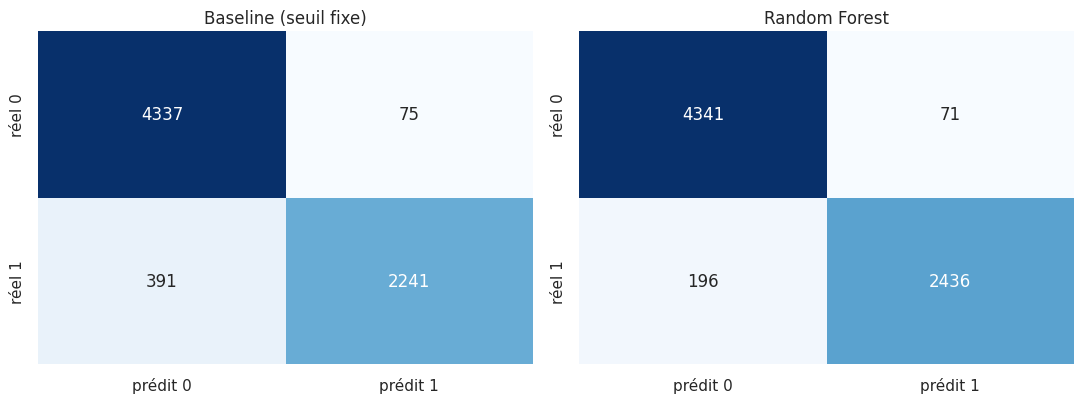

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for a, (nom, yp) in zip(ax, [("Baseline (seuil fixe)", y_pred_base), ("Random Forest", y_pred_rf)]):
    sns.heatmap(confusion_matrix(y_test, yp), annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["prédit 0", "prédit 1"], yticklabels=["réel 0", "réel 1"])
    a.set_title(nom)
plt.tight_layout(); plt.show()

### 11.1 Où la Random Forest gagne-t-elle vraiment ? (la zone frontière)

In [18]:
zone = X_test["soil_moisture_pct"].between(65, 95)
print(f"Lignes de test dans la zone 65-95 % : {zone.sum()}")
print(f"F1 baseline      : {f1_score(y_test[zone], y_pred_base[zone]):.3f}")
print(f"F1 Random Forest : {f1_score(y_test[zone], y_pred_rf[zone]):.3f}")

Lignes de test dans la zone 65-95 % : 4095
F1 baseline      : 0.774
F1 Random Forest : 0.882


💡 Loin du seuil, les deux méthodes ont presque toujours raison : sol très sec → arroser, sol plein → ne rien faire. **La différence se fait dans la zone frontière**, là où il faut **estimer la consommation à venir**. C'est l'argument à présenter au jury.

## 12. Qu'a appris le modèle ? (importance des variables)

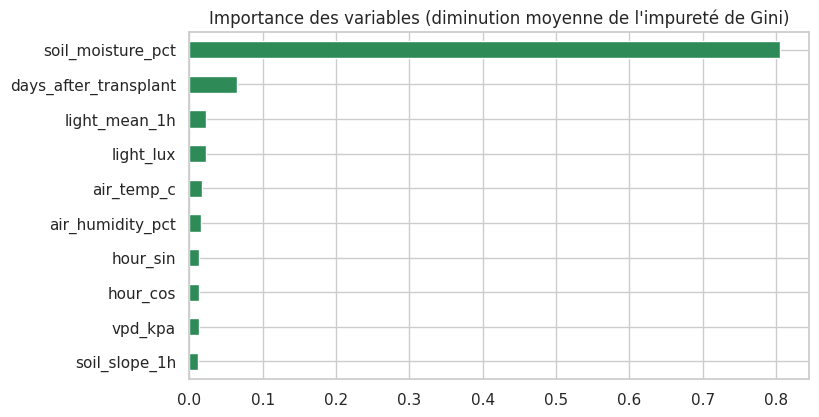

In [19]:
imp = pd.Series(rf.feature_importances_, index=FEATURES).sort_values()
imp.plot.barh(figsize=(8, 4.5), color="seagreen")
plt.title("Importance des variables (diminution moyenne de l'impureté de Gini)")
plt.show()

💡 **Interprétation physique**
- **`soil_moisture_pct` domine** : c'est la mesure du **réservoir**. Rassurant : le modèle a compris l'essentiel.
- **`days_after_transplant`** : en 6 semaines, le plant a environ **6 fois plus de feuilles** (de « panneaux solaires ») qu'à la plantation, donc il transpire beaucoup plus.
- **Lumière, VPD, température, heure** : elles estiment la **consommation à venir**. Attention : la nuit, une lumière de ~2 000 lx vient de la **lampe chauffante**, pas du soleil. La plante transpire alors surtout à cause de la chaleur et de l'air sec (VPD), presque pas à cause de la lumière. La température sert aussi à **corriger la dérive thermique** de la sonde capacitive : elle lit un peu « plus humide » quand le sol est chaud.

⚠️ Cette importance (dite « de Gini ») favorise les variables continues qui ont beaucoup de valeurs différentes. Une méthode plus fiable, l'**importance par permutation**, sera vue à l'étape suivante.

## 13. Aperçu : régler le seuil de décision pour réduire les faux négatifs

`predict()` répond 1 quand **plus de 50 % des arbres** votent 1. Mais rien n'oblige à garder 50 %. `predict_proba()` donne la proportion d'arbres qui votent 1, et on peut choisir notre propre seuil.

In [20]:
proba = rf.predict_proba(X_test)[:, 1]          # colonne 1 = probabilité de la classe "besoin d'eau"
lignes = []
for seuil in [0.5, 0.4, 0.3, 0.2]:
    yp = (proba >= seuil).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
    lignes.append({"seuil": seuil, "recall": recall_score(y_test, yp),
                   "precision": precision_score(y_test, yp), "faux négatifs": fn, "faux positifs": fp})
pd.DataFrame(lignes).round(3)

,seuil,recall,precision,faux négatifs,faux positifs
0,0.5,0.926,0.972,196,71
1,0.4,0.949,0.960,134,105
2,0.3,0.970,0.938,79,169
3,0.2,0.990,0.902,27,282


💡 **C'est un choix d'ingénieur, pas un choix mathématique.** Baisser le seuil attrape plus de besoins d'eau (moins de faux négatifs), au prix de plus d'arrosages inutiles. Comme la **couche de sécurité** limite déjà la durée de pompe, un seuil un peu plus bas que 0,5 est défendable pour une tomate.
⚠️ En toute rigueur, ce seuil devrait être choisi sur des données de **validation** (prises dans le train), pas sur le test. On le fait proprement à la section 14.

## 14. Régler les hyperparamètres (GridSearchCV + validation croisée par semaines)

Jusqu'ici, on a choisi `max_depth=12` et `min_samples_leaf=5` « au jugé ». On va maintenant **tester plusieurs réglages** et garder le meilleur, **sans toucher au test**.

**Comment ?** Par **validation croisée** : on découpe le **train** en 3 paquets de semaines. On entraîne sur 2 paquets, on évalue sur le 3ᵉ, et on recommence 3 fois en tournant. La moyenne des 3 scores dit si un réglage est bon.
**Analogie :** un élève qui révise avec 3 examens blancs différents avant le vrai examen (le test).

`GroupKFold` garantit qu'**une même semaine n'est jamais coupée en deux** entre entraînement et évaluation : même logique anti-fuite qu'à la section 8.

| Hyperparamètre | Ce qu'il contrôle | Trop petit | Trop grand |
|---|---|---|---|
| `max_depth` | nombre de questions successives dans un arbre | modèle trop simple (sous-apprentissage) | apprend le bruit (sur-apprentissage), modèle lourd |
| `min_samples_leaf` | nombre minimal d'exemples dans une feuille | décisions basées sur 1 ou 2 exemples bruités | modèle trop grossier |
| `class_weight` | poids donné à la classe minoritaire (« besoin d'eau ») | — | `"balanced"` pousse le modèle à moins rater les 1 |

⏱️ Cette cellule prend **2 à 5 minutes** dans Colab (36 forêts à entraîner).

In [21]:
from sklearn.model_selection import GridSearchCV, GroupKFold

groupes = semaine[~est_test].values           # numéro de semaine de chaque ligne du train

grille = {
    "max_depth": [8, 12, 16],
    "min_samples_leaf": [5, 20],
    "class_weight": [None, "balanced"],
}
recherche = GridSearchCV(
    RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
    param_grid=grille,
    scoring="f1",                  # on cherche le meilleur F1 de la classe 1
    cv=GroupKFold(n_splits=3),     # 3 « examens blancs » par paquets de semaines
    verbose=1,
)
recherche.fit(X_train, y_train, groups=groupes)

print("Meilleur réglage :", recherche.best_params_)
print(f"F1 moyen en validation croisée : {recherche.best_score_:.3f}")

(pd.DataFrame(recherche.cv_results_)[["params", "mean_test_score", "std_test_score"]]
   .sort_values("mean_test_score", ascending=False).head(6).round(3))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Meilleur réglage : {'class_weight': 'balanced', 'max_depth': 12, 'min_samples_leaf': 20}
F1 moyen en validation croisée : 0.948


,params,mean_test_score,std_test_score
9,"{'class_weight': 'balanced', 'max_depth': 12, ...",0.948,0.017
11,"{'class_weight': 'balanced', 'max_depth': 16, ...",0.947,0.018
7,"{'class_weight': 'balanced', 'max_depth': 8, '...",0.944,0.019
2,"{'class_weight': None, 'max_depth': 12, 'min_s...",0.943,0.026
4,"{'class_weight': None, 'max_depth': 16, 'min_s...",0.943,0.027
5,"{'class_weight': None, 'max_depth': 16, 'min_s...",0.942,0.024


🔎 **Ligne par ligne**
- `grille` : toutes les combinaisons sont testées (3 × 2 × 2 = **12 réglages**), chacune 3 fois → 36 entraînements.
- `scoring="f1"` : le critère pour comparer les réglages. On n'utilise pas l'accuracy (piège de la section 5.2).
- `recherche.fit(..., groups=groupes)` : `groups` indique à `GroupKFold` quelles lignes appartiennent à la même semaine.
- `best_params_` : le réglage gagnant. `GridSearchCV` **ré-entraîne automatiquement** ce réglage sur **tout** le train : c'est `recherche.best_estimator_`.
- `std_test_score` : l'écart-type entre les 3 examens blancs. S'il est grand, le score dépend beaucoup des semaines choisies : le modèle est moins **stable**.

💡 Si plusieurs réglages ont presque le même score, préfère le **plus simple** (profondeur plus faible, feuilles plus grandes) : il sera plus léger sur le Raspberry Pi et généralisera mieux.

### 14.1 Choisir le seuil de décision proprement (sans regarder le test)

À la section 13, on a vu qu'abaisser le seuil réduit les faux négatifs. On le choisit maintenant **sur le train**, avec des probabilités obtenues en validation croisée (chaque ligne est prédite par un modèle qui ne l'a jamais vue).

**Critère : le F2-score.** C'est un F1 qui donne **2 fois plus d'importance au recall** qu'à la precision. Pour une tomate, rater une soif (faux négatif) est plus grave qu'arroser un peu trop (faux positif), surtout que la couche de sécurité limite la durée de pompe.

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import fbeta_score

meilleur_rf = recherche.best_estimator_

proba_cv = cross_val_predict(meilleur_rf, X_train, y_train, groups=groupes,
                             cv=GroupKFold(n_splits=3), method="predict_proba")[:, 1]

seuils_dec = np.round(np.arange(0.10, 0.90, 0.05), 2)
f2 = [fbeta_score(y_train, (proba_cv >= s).astype(int), beta=2) for s in seuils_dec]
SEUIL = float(seuils_dec[int(np.argmax(f2))])
print("Seuil de décision retenu (meilleur F2 en validation croisée) :", SEUIL)

plt.figure(figsize=(8, 3.5))
plt.plot(seuils_dec, f2, marker="o")
plt.axvline(SEUIL, color="red", ls="--")
plt.xlabel("seuil de décision"); plt.ylabel("F2 (validation croisée)")
plt.show()

🔎 `cross_val_predict(..., method="predict_proba")` renvoie, pour chaque ligne du train, la probabilité « besoin d'eau » prédite par un modèle **entraîné sans cette ligne**. On teste ensuite 16 seuils et on garde celui qui maximise le F2.

### 14.2 Évaluation finale sur le test (une seule fois !)

In [ ]:
proba_test = meilleur_rf.predict_proba(X_test)[:, 1]
y_pred_final = (proba_test >= SEUIL).astype(int)

final = pd.DataFrame([evaluer(f"Baseline : sol < {S_best} %", y_test, y_pred_base),
                      evaluer("Random Forest initiale (seuil 0,5)", y_test, y_pred_rf),
                      evaluer(f"Random Forest réglée (seuil {SEUIL})", y_test, y_pred_final)])
final.round(3)

💡 **C'est ce tableau qu'on présente au jury** (en rappelant que les données sont simulées). Le modèle final réduit fortement les faux négatifs par rapport à la règle simple, en échange de quelques arrosages inutiles supplémentaires.
Le test n'a servi **qu'à cette mesure finale** : tous les choix (hyperparamètres, seuil) ont été faits sur le train.

## 15. Sauvegarder le modèle pour le Raspberry Pi

**Entraîner** (ce qu'on vient de faire) se fait **une fois**, sur Colab. **Prédire** (l'inférence) se fera **en boucle sur le Pi**, toutes les 10 minutes. On sauvegarde donc tout ce dont le Pi a besoin dans **un seul fichier** :
- le modèle ;
- la **liste et l'ordre des features** : si l'ordre change, le modèle donne n'importe quoi sans afficher d'erreur ;
- le **seuil de décision** ;
- la **version de scikit-learn** : le Pi doit avoir la même, sinon le fichier risque de ne pas se charger.

In [ ]:
import joblib, os

paquet = {
    "modele": meilleur_rf,
    "features": FEATURES,
    "seuil_decision": SEUIL,
    "version_sklearn": sklearn.__version__,
}
joblib.dump(paquet, "modele_irrigation_tomate.joblib", compress=3)

taille_mo = os.path.getsize("modele_irrigation_tomate.joblib") / 1e6
print(f"Taille du fichier : {taille_mo:.2f} Mo")

paquet_charge = joblib.load("modele_irrigation_tomate.joblib")   # vérification : on le relit
print("Features attendues :", paquet_charge["features"])
print("Seuil :", paquet_charge["seuil_decision"], "| scikit-learn :", paquet_charge["version_sklearn"])

🔎 **Ligne par ligne**
- `joblib.dump(objet, fichier, compress=3)` : écrit l'objet Python sur le disque. `compress=3` réduit la taille (environ 3 à 4 fois) au prix d'un chargement un peu plus lent, ce qui ne pose aucun problème : le Pi ne charge le modèle qu'une fois au démarrage.
- `joblib.load(...)` : l'opération inverse, exactement ce que fera le Pi.
- **Sur le Raspberry Pi**, il faudra installer la même version : `pip install scikit-learn==<version affichée>`.

In [ ]:
# Télécharger le fichier du modèle sur ton ordinateur (pour le copier ensuite sur le Pi)
try:
    from google.colab import files
    files.download("modele_irrigation_tomate.joblib")
except ImportError:
    print("Hors de Colab : le fichier est dans le dossier courant.")

## 16. Simuler une décision comme sur le Raspberry Pi

Sur le Pi, on n'aura pas un tableau de 36 000 lignes, mais **une mesure à la fois**. Il faut donc recalculer les **mêmes features**, avec **les mêmes formules**, à partir des capteurs et d'un petit historique (la mesure d'il y a 1 h, la lumière de la dernière heure).

In [ ]:
import time

def recommander_irrigation(paquet, m):
    # m : dictionnaire avec les mesures actuelles + un peu d'historique
    es = 0.6108 * np.exp(17.27 * m["air_temp_c"] / (m["air_temp_c"] + 237.3))
    ligne = {
        "soil_moisture_pct": m["soil_moisture_pct"],
        "air_temp_c": m["air_temp_c"],
        "air_humidity_pct": m["air_humidity_pct"],
        "light_lux": m["light_lux"],
        "light_mean_1h": m["light_mean_1h"],
        "vpd_kpa": es * (1 - m["air_humidity_pct"] / 100),
        "hour_sin": np.sin(2 * np.pi * m["heure"] / 24),
        "hour_cos": np.cos(2 * np.pi * m["heure"] / 24),
        "soil_slope_1h": m["soil_moisture_pct"] - m["soil_moisture_pct_il_y_a_1h"],
        "days_after_transplant": m["days_after_transplant"],
    }
    X_new = pd.DataFrame([ligne])[paquet["features"]]          # même ordre qu'à l'entraînement
    proba = paquet["modele"].predict_proba(X_new)[0, 1]
    return proba, int(proba >= paquet["seuil_decision"])


def couche_securite(besoin_eau, niveau_reservoir_pct, flamme):
    # Règles dures, prioritaires sur le modèle
    if flamme:
        return "🔥 ALARME : buzzer ON, pompe et lampe coupées"
    if besoin_eau and niveau_reservoir_pct < 10:
        return "⚠️ Besoin d'eau mais réservoir vide : pompe bloquée, buzzer ON"
    return "💧 Arroser : impulsion de pompe de 10 s" if besoin_eau else "✅ Ne rien faire"


# Même sol à 80 %, deux moments de la journée
matin_soleil = dict(soil_moisture_pct=80, soil_moisture_pct_il_y_a_1h=84, air_temp_c=27, air_humidity_pct=45,
                    light_lux=35000, light_mean_1h=33000, heure=11, days_after_transplant=35)
nuit = dict(soil_moisture_pct=80, soil_moisture_pct_il_y_a_1h=80.5, air_temp_c=19, air_humidity_pct=75,
            light_lux=0, light_mean_1h=0, heure=23, days_after_transplant=35)

for nom, m in [("11 h, plein soleil", matin_soleil), ("23 h, nuit", nuit)]:
    t0 = time.perf_counter()
    proba, besoin = recommander_irrigation(paquet_charge, m)
    duree_ms = (time.perf_counter() - t0) * 1000
    print(f"{nom:20s} | sol 80 % | proba besoin = {proba:.2f} | décision : "
          f"{couche_securite(besoin, niveau_reservoir_pct=60, flamme=False)} | {duree_ms:.0f} ms")

💡 **La démonstration clé pour le jury.** Avec **exactement la même humidité du sol (80 %)** :
- à **11 h en plein soleil**, le sol a perdu 4 points en 1 h, la plante boit vite : **le modèle recommande d'arroser** ;
- à **23 h**, la plante ne boit presque rien : **pas besoin d'arroser**.

Un `if sol < 76 %` ne ferait **pas** cette différence. C'est toute la valeur du modèle.

🔎 **À retenir pour le code du Pi**
- Les features doivent être calculées **exactement** comme à l'entraînement : mêmes formules, mêmes unités, même ordre (`paquet["features"]`).
- Le temps de prédiction affiché ici concerne les serveurs de Google. Sur un Raspberry Pi 3, compte environ **10 fois plus**, ce qui reste négligeable pour une décision toutes les 10 minutes.
- La **couche de sécurité** passe **après** le modèle et peut toujours le contredire (flamme, réservoir vide).

## 17. À retenir

1. Le label ne dit pas « le sol est sec » mais **« la réserve ne tiendra pas 3 heures »**. Il faut donc combiner **réserve** (capteur de sol) et **consommation** (lumière, chaleur, sécheresse de l'air, taille de la plante).
2. Les capteurs réels ont des **défauts** (lectures ratées, parasites, saturation, dérive). Le nettoyage doit être **causal** : n'utiliser que le passé.
3. Le split **par semaines** évite la fuite de données due aux mesures voisines.
4. On compare toujours à une **baseline**. Le gain se concentre dans la **zone frontière**.
5. Les réglages (hyperparamètres, seuil de décision) se choisissent par **validation croisée sur le train**. Le test ne sert qu'**une fois**, à la fin.
6. Le Pi reçoit **un seul fichier** : modèle + liste des features + seuil + version de scikit-learn.
7. Ces chiffres valent pour une **simulation**. La vraie validation se fera sur vos propres enregistrements.

## 18. Exercices

**Exercice 1 : la fuite de données.** Remplace le split par semaines par
`from sklearn.model_selection import train_test_split`
`X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)`
puis ré-entraîne. Le F1 monte-t-il ? Explique pourquoi ce score est **trompeur**.

**Exercice 2 : la triche évidente.** Ajoute `sim_soil_true_pct` aux `FEATURES`. Que devient le F1 ? Pourquoi cette colonne est-elle **interdite**, alors qu'elle améliore le score ?

**Exercice 3 : à quoi sert chaque capteur ?** Retire `light_lux` et `light_mean_1h`, puis ré-entraîne. Que deviennent le recall et le nombre de faux négatifs ? Qu'est-ce que ça dit sur l'intérêt du BH1750 ?

**Exercice 4 : jury.** En 3 phrases, explique pourquoi un `if sol < 70` ne suffit pas, en t'appuyant sur le graphique 5.3.

In [ ]:
# Exercice 1 : écris ton code ici

In [ ]:
# Exercice 2 : écris ton code ici

In [ ]:
# Exercice 3 : écris ton code ici